# Generar figuras con volumen y fondo de burbujas

La notebook dibuja las figuras con sombreado 3D y las compone sobre un fondo celeste claro con burbujas de bajo contraste. Después genera el estereograma Magic Eye de la estrella. Los PNG se guardan en `backend/media/challenges/shaded_3d`, sin modificar las imágenes de desafíos existentes.

In [2]:
from pathlib import Path
import sys

from PIL import Image

current_dir = Path.cwd().resolve()
search_dirs = [current_dir, *current_dir.parents]
backend_dir = next(
    (path for path in search_dirs if (path / "geom_challenges" / "figures.py").is_file()),
    None,
)
if backend_dir is None:
    backend_dir = next(
        (path / "backend" for path in search_dirs if (path / "backend" / "geom_challenges" / "figures.py").is_file()),
        None,
    )
if backend_dir is None:
    raise FileNotFoundError("No se encontró backend/geom_challenges/figures.py desde el directorio actual.")

if str(backend_dir) not in sys.path:
    sys.path.insert(0, str(backend_dir))

from geom_challenges.constants import BORDER_WIDTH, FIGURE_NAMES, SHAPE_COLORS
from geom_challenges.services.figure_generator import FiguresGenerator

print(f"Backend: {backend_dir}")

Backend: C:\Users\anavi\My Code\backend


In [19]:
from random import Random
from PIL import ImageChops, ImageDraw


def create_bubble_background(
    size,
    seed=2026,
    bubble_count=3200,
    radius_range=(4, 10),
    tile_x=False,
    background_color="#dceefa",
    bubble_color="#edf9ff",
    outline_color="#69b5d3",
    shadow_color="#5d9fbd",
    details_per_bubble=4,
    detail_radius_range=(1, 3),
):
    """Create a dense baby-blue field of glossy, three-dimensional bubbles."""
    background = Image.new("RGB", size, background_color)
    draw = ImageDraw.Draw(background)
    randomizer = Random(seed)
    width, height = size
    horizontal_offsets = (-width, 0, width) if tile_x else (0,)
    bubble_rgb = tuple(int(bubble_color[index:index + 2], 16) for index in (1, 3, 5))
    highlight_color = tuple(
        min(255, int(channel + (255 - channel) * 0.65))
        for channel in bubble_rgb
    )

    for _ in range(bubble_count):
        radius = randomizer.randint(*radius_range)
        center_x = randomizer.randint(0, width)
        center_y = randomizer.randint(-radius, height + radius)

        for offset_x in horizontal_offsets:
            x = center_x + offset_x
            bounds = (
                x - radius,
                center_y - radius,
                x + radius,
                center_y + radius,
            )
            draw.ellipse(bounds, fill=shadow_color, outline=outline_color, width=1)

            face_inset = max(1, radius // 4)
            face_bounds = (
                x - radius + face_inset,
                center_y - radius + face_inset,
                x + radius - face_inset,
                center_y + radius - face_inset,
            )
            draw.ellipse(face_bounds, fill=bubble_color)

            highlight_radius = max(1, radius // 3)
            highlight_bounds = (
                x - radius // 2 - highlight_radius,
                center_y - radius // 2 - highlight_radius,
                x - radius // 2 + highlight_radius,
                center_y - radius // 2 + highlight_radius,
            )
            draw.ellipse(highlight_bounds, fill=highlight_color)
            draw.arc(bounds, start=205, end=320, fill="#ffffff", width=1)
            draw.arc(bounds, start=20, end=150, fill=shadow_color, width=1)

            for _ in range(details_per_bubble):
                detail_radius = randomizer.randint(*detail_radius_range)
                detail_x = randomizer.randint(x - radius // 2, x + radius // 2)
                detail_y = randomizer.randint(
                    center_y - radius // 2,
                    center_y + radius // 2,
                )
                detail_bounds = (
                    detail_x - detail_radius,
                    detail_y - detail_radius,
                    detail_x + detail_radius,
                    detail_y + detail_radius,
                )
                draw.ellipse(
                    detail_bounds,
                    fill=highlight_color if randomizer.random() < 0.7 else shadow_color,
                    outline=outline_color,
                    width=1,
                )
                draw.point((detail_x - 1, detail_y - 1), fill="#ffffff")

    return background


output_dir = backend_dir / "media" / "challenges" / "shaded_3d"
output_dir.mkdir(parents=True, exist_ok=True)

generator = FiguresGenerator()
generated_paths = []
white_background = Image.new("RGB", (800, 600), color="white")

for index, figure_name in enumerate(FIGURE_NAMES):
    color = SHAPE_COLORS[index % len(SHAPE_COLORS)]
    figure_image = white_background.copy()
    figure = generator.create_figure(figure_name)
    figure.draw(figure_image, color=color, fill_color=color, border_width=BORDER_WIDTH)
    figure.apply_3d_shading(figure_image)

    difference = ImageChops.difference(figure_image, white_background).convert("L")
    figure_mask = difference.point(lambda value: 255 if value > 8 else 0)
    image = create_bubble_background(figure_image.size)
    image.paste(figure_image, (0, 0), figure_mask)

    output_path = output_dir / f"{figure_name}.png"
    image.save(output_path, format="PNG")
    generated_paths.append(output_path)

print(f"Generadas {len(generated_paths)} de {len(FIGURE_NAMES)} figuras en: {output_dir}")
[path.name for path in generated_paths]

Generadas 20 de 20 figuras en: C:\Users\anavi\My Code\backend\media\challenges\shaded_3d


['square.png',
 'circle.png',
 'rectangle.png',
 'ellipse.png',
 'triangle.png',
 'pentagon.png',
 'hexagon.png',
 'star.png',
 'sun.png',
 'flower.png',
 'crescent.png',
 'heart.png',
 'cross.png',
 'pacman.png',
 'droplet.png',
 'diagonal.png',
 'arrow.png',
 'spiral.png',
 'rainbow.png',
 'text.png']

Mapa de profundidad guardado en: C:\Users\anavi\My Code\backend\media\challenges\shaded_3d\star_depth_map.png
Estereograma guardado en: C:\Users\anavi\My Code\backend\media\challenges\shaded_3d\star_magic_eye_corrected.png (parámetros: 90-0.3-0.5)


**Entrada:** estrella visible. **Mapa:** estrella blanca = zona elevada. **Magic Eye:** la forma queda oculta en el patrón y se aprecia al fusionar la vista.

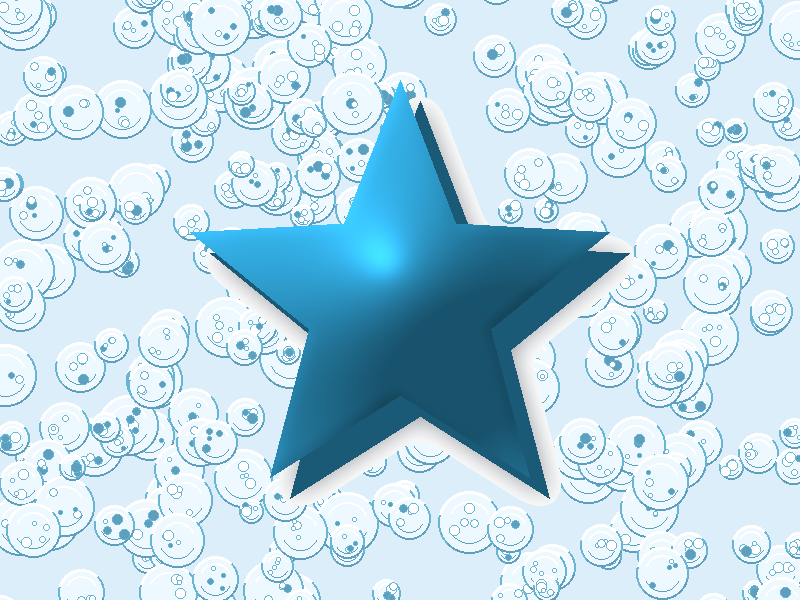

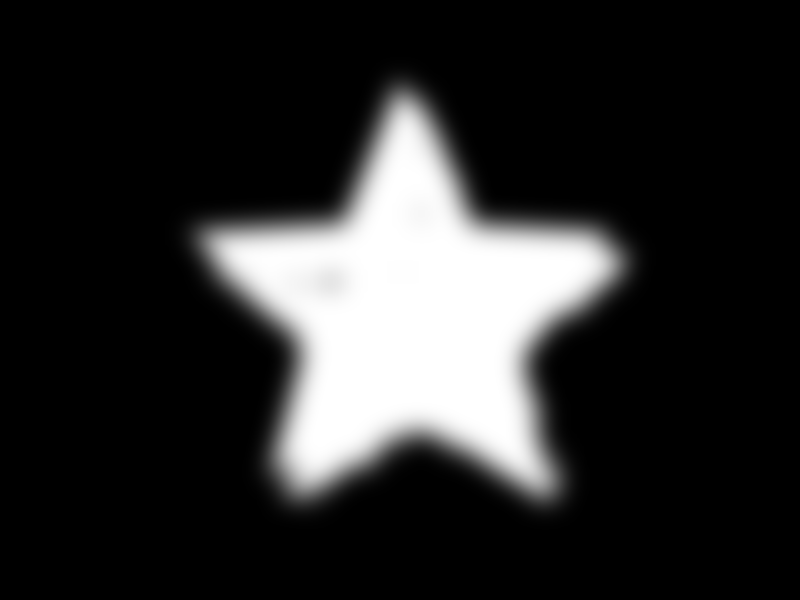

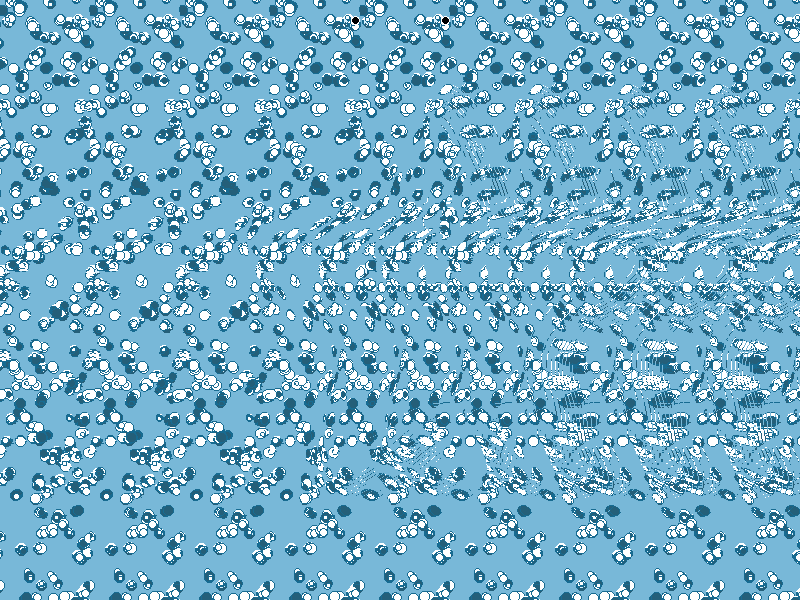

In [ ]:
import importlib
from IPython.display import Markdown, display
from PIL import ImageFilter

import geom_challenges.services.magic_eye as magic_eye_module
MagicEye = importlib.reload(magic_eye_module).MagicEye

star_path = output_dir / "star.png"
if not star_path.is_file():
    raise FileNotFoundError(f"No se encontró la imagen de la estrella: {star_path}")

with Image.open(star_path) as source_image:
    star_with_bubbles = source_image.convert("RGB")

bubble_background = create_bubble_background(star_with_bubbles.size)
shape_difference = ImageChops.difference(star_with_bubbles, bubble_background).convert("L")
star_mask = shape_difference.point(lambda value: 255 if value > 18 else 0)
depth_map = star_mask.filter(ImageFilter.GaussianBlur(radius=12))
if depth_map.getextrema()[1] < 200:
    raise ValueError("No se pudo extraer una silueta clara de la estrella para el mapa de profundidad.")

depth_map_path = output_dir / "star_depth_map.png"
depth_map.save(depth_map_path, format="PNG")

pattern_width = 90
bubble_texture = create_bubble_background(
    (pattern_width, star_with_bubbles.height),
    seed=2026,
    bubble_count=2400,
    radius_range=(1, 2),
    tile_x=True,
    background_color="#78b8d8",
    bubble_color="#d7f2ff",
    outline_color="#176b91",
    shadow_color="#245f79",
    details_per_bubble=1,
    detail_radius_range=(1, 1),
)
magic_eye_image, magic_eye_settings = MagicEye(
    star_with_bubbles,
    ancho_patron=pattern_width,
    object_3d=0.3,
).crear_ojo_magico_pro(
    image_texture=bubble_texture,
    depth_map=depth_map,
)
magic_eye_path = output_dir / "star_magic_eye_corrected.png"
magic_eye_image.save(magic_eye_path, format="PNG")

print(f"Mapa de profundidad guardado en: {depth_map_path}")
print(f"Estereograma guardado en: {magic_eye_path} (parámetros: {magic_eye_settings})")
display(Markdown("**Entrada:** estrella visible. **Mapa:** estrella blanca = zona elevada. **Magic Eye:** la forma queda oculta en el patrón y se aprecia al fusionar la vista."))
display(star_with_bubbles)
display(depth_map)
display(magic_eye_image)